In [1]:
# Imports
import kagglehub
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:
# Path to the dataset
DATA_DIR = kagglehub.competition_download('cassava-leaf-disease-classification')
IMG_DIR = os.path.join(DATA_DIR, "train_images")

In [3]:
# Initialize a fresh, reproducible random number generator
SEED = 42
np.random.seed(SEED)

# Load the labels file and the label-to-disease name mapping
df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
with open(os.path.join(DATA_DIR, "label_num_to_disease_map.json")) as f:
    label_map = {int(k): v for k, v in json.load(f).items()}

df["disease"] = df["label"].map(label_map)
df.shape

(21397, 3)

In [4]:
df.isna().sum()

image_id    0
label       0
disease     0
dtype: int64

In [5]:
label_map

{0: 'Cassava Bacterial Blight (CBB)',
 1: 'Cassava Brown Streak Disease (CBSD)',
 2: 'Cassava Green Mottle (CGM)',
 3: 'Cassava Mosaic Disease (CMD)',
 4: 'Healthy'}

In [6]:
df["disease"].value_counts()

disease
Cassava Mosaic Disease (CMD)           13158
Healthy                                 2577
Cassava Green Mottle (CGM)              2386
Cassava Brown Streak Disease (CBSD)     2189
Cassava Bacterial Blight (CBB)          1087
Name: count, dtype: int64

In [7]:
(df["disease"].value_counts(normalize=True) * 100).round(2)

disease
Cassava Mosaic Disease (CMD)           61.49
Healthy                                12.04
Cassava Green Mottle (CGM)             11.15
Cassava Brown Streak Disease (CBSD)    10.23
Cassava Bacterial Blight (CBB)          5.08
Name: proportion, dtype: float64

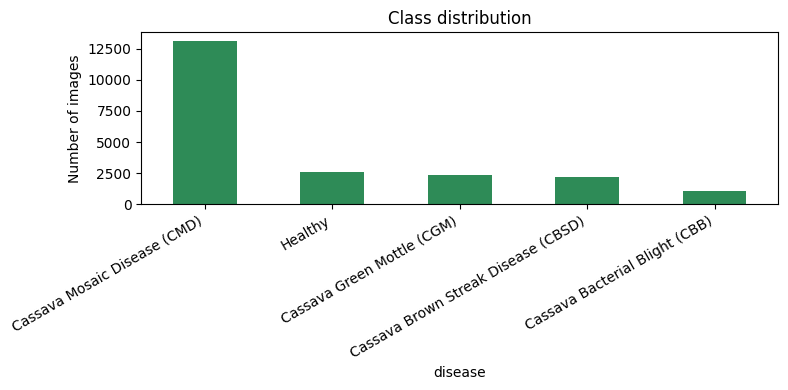

In [8]:
# Plot the class distribution to see the imbalance
df["disease"].value_counts().plot(kind="bar", color="seagreen", figsize=(8, 4))
plt.title("Class distribution")
plt.ylabel("Number of images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

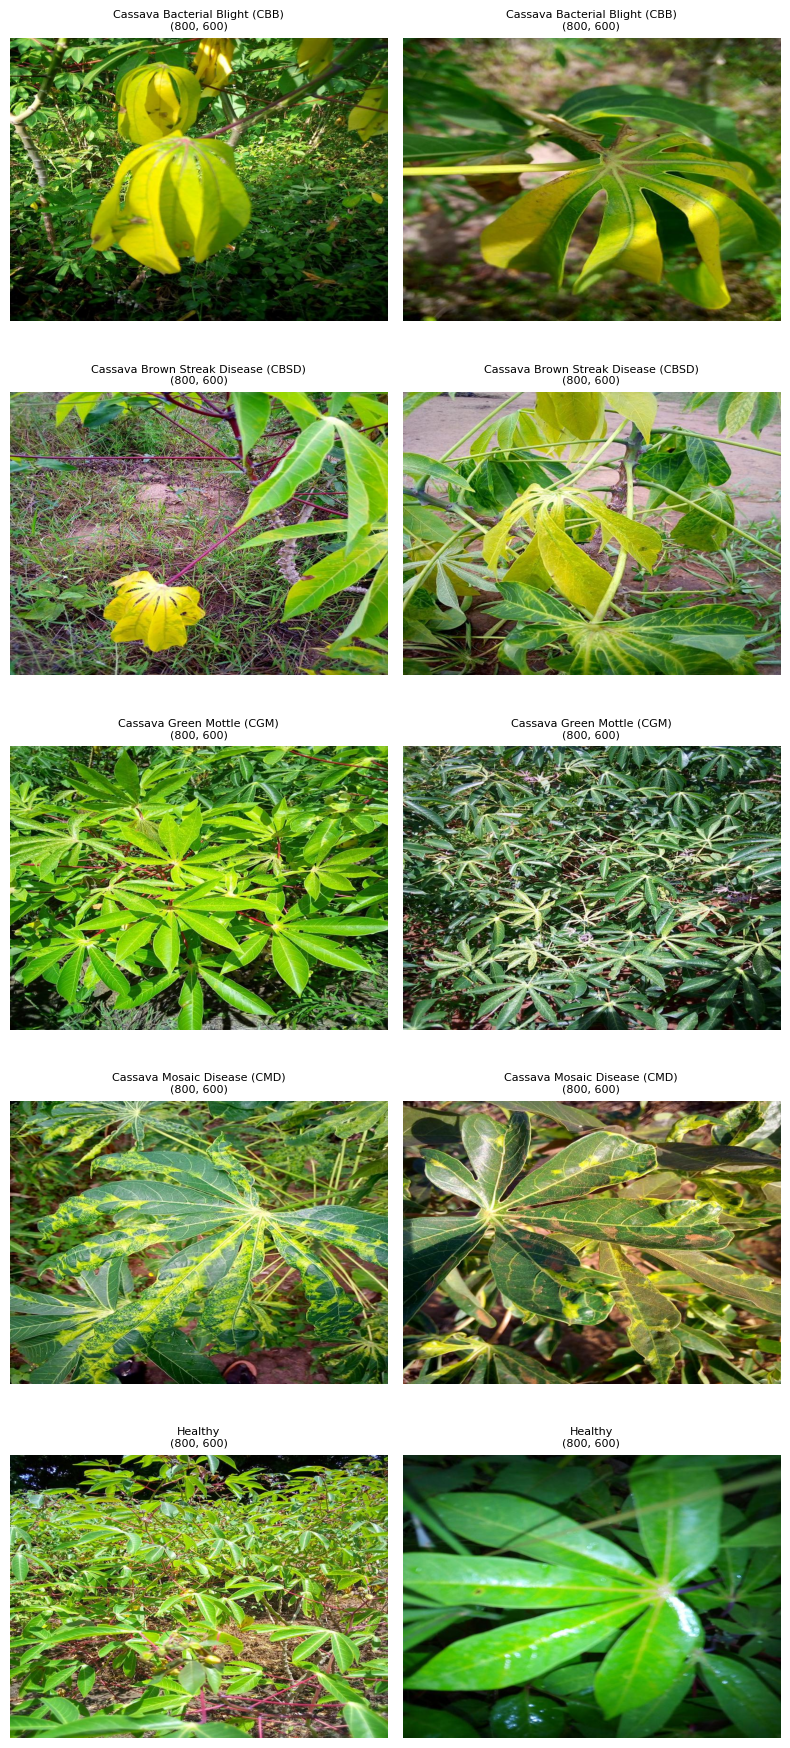

In [9]:
# Show 2 sample images per class
fig, axes = plt.subplots(5, 2, figsize=(8, 18))
for row, (lbl, name) in enumerate(sorted(label_map.items())):
    samples = df[df["label"] == lbl].sample(2, random_state=SEED)
    for col, (_, r) in enumerate(samples.iterrows()):
        img = Image.open(os.path.join(IMG_DIR, r["image_id"]))
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{name}\n{img.size}", fontsize=8)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

### Data Exploration Findings.
The dataset contains 21,397 labeled images with no missing values. And we saw that sample images are 800x600 RGB field photographs.

The class distribution is strongly imbalanced. Cassava Mosaic Disease (CMD) accounts for 61.5% of the images (13,158), while Cassava Bacterial Blight (CBB) makes up only 5.1% (1,087). A model that always predicts CMD would reach about 61% accuracy while being useless for the other diseases, so accuracy alone is not a trustworthy metric here. Macro-F1 and per-class precision/recall will be the primary metrics, and class weights will be used to handle the imbalance.

The sample images also show real-world difficulty: images have cluttered backgrounds, varying lighting, and some diseases (e.g: CGM vs Healthy) look visually similar, which suggests these classes will be harder to separate.

In [10]:
from sklearn.model_selection import train_test_split

# Build the full path to every image so we can load files directly later
df["filepath"] = IMG_DIR + "/" + df["image_id"]

# First split: holds 15% as the final test set
train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df["label"], random_state=SEED
)

# Second split: from the remaining 85%, holds 17.6% (which is equal to 15% of the total) as validation
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1765, stratify=train_val_df["label"], random_state=SEED
)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# Confirm that class proportions are preserved in every split
summary = pd.DataFrame({
    "train_%": train_df["disease"].value_counts(normalize=True) * 100,
    "val_%":   val_df["disease"].value_counts(normalize=True) * 100,
    "test_%":  test_df["disease"].value_counts(normalize=True) * 100,
}).round(2)
print(summary)

# Check if no image appears in more than one split
assert set(train_df.image_id).isdisjoint(val_df.image_id)
assert set(train_df.image_id).isdisjoint(test_df.image_id)
assert set(val_df.image_id).isdisjoint(test_df.image_id)
print("No overlap between splits")

# Save the splits so every later experiment uses exactly the same data
train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)

Train: 14976 | Val: 3211 | Test: 3210
                                     train_%  val_%  test_%
disease                                                    
Cassava Mosaic Disease (CMD)           61.49  61.51   61.50
Healthy                                12.04  12.05   12.06
Cassava Green Mottle (CGM)             11.15  11.15   11.15
Cassava Brown Streak Disease (CBSD)    10.24  10.21   10.22
Cassava Bacterial Blight (CBB)          5.08   5.08    5.08
No overlap between splits


In [11]:
#Checking every image’s size, mode, and readability
from collections import Counter
from joblib import Parallel, delayed

def inspect_image(path):
    """Read image header and report the size and color mode flag those that are unreadable."""
    try:
        with Image.open(path) as img:
            return img.size, img.mode, None
    except Exception as e:
        return None, None, str(e)

results = Parallel(n_jobs=-1)(delayed(inspect_image)(p) for p in df["filepath"])

sizes  = Counter(r[0] for r in results if r[0] is not None)
modes  = Counter(r[1] for r in results if r[1] is not None)
errors = [(p, r[2]) for p, r in zip(df["filepath"], results) if r[2] is not None]

print("Image sizes (width, height):", sizes.most_common())
print("Color modes:", modes.most_common())
print("Unreadable files:", len(errors))

Image sizes (width, height): [((800, 600), 21397)]
Color modes: [('RGB', 21397)]
Unreadable files: 0


### Feature Engineering for Traditional ML
Scikit-learn models cannot take raw images directly, so each image is converted into a fixed-length numeric vector. Experiment E1 uses colour-based features, which are meaningful for leaf disease: mosaic and blight symptoms change the colour pattern of the leaf (yellowing, mottling, browning).

For every image we compute:
- A 32-bin histogram for each of the H, S and V channels (HSV colour space), which captures the colour distribution and is less sensitive to lighting than RGB.
- The mean and standard deviation of each R, G, B, H, S, V channel.

This gives 108 features per image. Images are first resized to 128x128 to keep extraction fast and to guarantee a consistent input regardless of the original size.

In [12]:
def extract_color_features(path, size=(128, 128), bins=32):
    """Turn one image into a feature vector."""
    img = Image.open(path).convert("RGB").resize(size)   
    rgb = np.asarray(img, dtype=np.float32)
    hsv = np.asarray(img.convert("HSV"), dtype=np.float32)

    feats = []
    # 32-bin histogram per HSV channel, normalised so each sums to 1
    for c in range(3):
        hist, _ = np.histogram(hsv[:, :, c], bins=bins, range=(0, 255))
        feats.extend(hist / hist.sum())
    # mean and std per channel for RGB and HSV
    for arr in (rgb, hsv):
        for c in range(3):
            feats.append(arr[:, :, c].mean())
            feats.append(arr[:, :, c].std())
    return np.array(feats, dtype=np.float32)

def build_feature_matrix(frame):
    X = Parallel(n_jobs=-1)(delayed(extract_color_features)(p) for p in frame["filepath"])
    return np.vstack(X), frame["label"].values

X_train, y_train = build_feature_matrix(train_df)
X_val,   y_val   = build_feature_matrix(val_df)
X_test,  y_test  = build_feature_matrix(test_df)

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("NaNs in features:", np.isnan(X_train).sum())

# Save so we don't have to recompute if the session restarts
np.savez_compressed("color_features.npz",
                    X_train=X_train, y_train=y_train,
                    X_val=X_val, y_val=y_val,
                    X_test=X_test, y_test=y_test)

X_train: (14976, 108) | X_val: (3211, 108) | X_test: (3210, 108)
NaNs in features: 0
